# Dynamic case generation (offshore-waves forcing)

Workflow:

1. Load **goals** from the case JSON → `simulations.goals_file`.
2. Open a **processed offshore-waves** zarr (`offshore_waves` in the case JSON).
3. Build SnapWave boundary forcing per timestep (`hs`, `tp`, `wd`, `ds`).
4. Run cases (optional) and postprocess to a single time-series NetCDF.

Processed offshore data must use dims `(time, goal)` with bulk variables
`hs`, `tp`, `dir`, `spr` (see `07_Download_Process_WHACS.ipynb`).

In [1]:
from utils.config import (
    PATHS,
    SIMULATIONS,
    get_offshore_wave,
    goals_for_snapwave,
    load_goals,
    open_offshore_waves,
    resolve,
)
from utils.simulation.offshore_forcing import boundary_parameters
from utils.simulation.snapwave_wrappers import SnapWaveDynamicModelWrapper

## Configuration

In [2]:
offshore_name = "WHACS"  # must match an entry in the case JSON → offshore_waves
period = "2010"  # time slice passed to xarray .sel(time=...)

offshore_entry = get_offshore_wave(offshore_name)
templates_dir = resolve(SIMULATIONS["dynamic_templates"])
cases_dir = resolve(SIMULATIONS["dynamic_cases"])
aoi_file = resolve(PATHS["aoi_file"])
mesh_file = resolve(PATHS["mesh_file"])
goals_file = resolve(SIMULATIONS["goals_file"])
offshore_path = resolve(offshore_entry["data_path"])
raw_goals = load_goals()

print(f"offshore  : {offshore_name} → {offshore_path}")
print(f"goals     : {goals_file}")
print(f"templates : {templates_dir}")
print(f"cases     : {cases_dir}")
print(f"mesh      : {mesh_file}")
print(f"period    : {period}")

offshore  : WHACS → /home/tausiaj/GitHub-GeoOcean/HyGloW/NewSouthWales/inputs/WHACS/processed/NewSouthWales_WHACS_goal.zarr
goals     : /home/tausiaj/GitHub-GeoOcean/HyGloW/NewSouthWales/inputs/Goals/NewSouthWales_Goals.json
templates : /home/tausiaj/GitHub-GeoOcean/HyGloW/NewSouthWales/templates-dynamic
cases     : /hyglowdata/NewSouthWales/SnapWave_CASES_Dynamic
mesh      : /home/tausiaj/GitHub-GeoOcean/HyGloW/NewSouthWales/inputs/GRID/NewSouthWales_mesh.nc
period    : 2010


## Offshore waves → boundary forcing

In [3]:
offshore_ds = open_offshore_waves(entry=offshore_entry).sel(time=period).load()
offshore_ds

<xarray.Dataset> Size: 37MB
Dimensions:   (time: 8760, goal: 26)
Coordinates:
  * time      (time) datetime64[ns] 70kB 2010-01-01 ... 2010-12-31T23:00:00
  * goal      (goal) int64 208B 1 2 3 4 5 6 7 8 9 ... 18 19 20 21 22 23 24 25 26
    seapoint  (goal) int64 208B 923284 937305 937042 ... 930128 929894 922215
Data variables: (12/20)
    dir       (time, goal) float64 2MB 68.5 69.4 68.8 67.4 ... 30.4 27.0 44.9
    hs        (time, goal) float64 2MB 1.378 1.576 1.57 ... 1.982 2.054 1.702
    pdir0     (time, goal) float64 2MB nan 61.7 59.5 56.0 ... 31.1 29.9 26.8 nan
    pdir1     (time, goal) float64 2MB 64.3 151.9 147.5 ... 192.4 187.6 43.9
    pdir2     (time, goal) float64 2MB 144.1 184.8 186.7 ... 26.5 230.0 186.2
    pdir3     (time, goal) float64 2MB 88.9 2.6 0.9 0.7 ... nan nan 191.5 187.8
    ...        ...
    ptp0      (time, goal) float64 2MB nan 7.29 7.22 6.98 ... 6.6 6.96 7.03 nan
    ptp1      (time, goal) float64 2MB 7.37 6.47 6.4 6.4 ... 13.34 9.22 7.23
    ptp2      (time, goal) float64 2MB 6.44 9.53 9.46 9.34 ... 11.12 12.35 8.5
    ptp3      (time, goal) float64 2MB 15.24 11.23 11.46 ... nan 13.48 13.35
    spr       (time, goal) float64 2MB 32.9 41.2 43.3 44.7 ... 34.4 35.6 29.5
    tp        (time, goal) float64 2MB 7.092 6.993 6.897 ... 6.993 7.042 7.246
Attributes: (12/59)
    Conventions:                     CF-1.11 ACDD-1.3
    title:                           Wave Hindcast for the Australian Climate...
    summary:                         Wave Hindcast for the Australian Climate...
    keywords:                        WHACS, ACS, waves, ocean, coast, WWIII, ...
    id:                              BoM-CSIRO-WHACS-001
    naming_authority:                au.csiro
    ...                              ...
    geospatial_lon_max:              179.9375
    geospatial_vertical_positive:    up
    time_coverage_start:             1979-01-01T00:00:00
    time_coverage_end:               1979-01-31T23:00:00
    time_coverage_duration:          P30DT23H0M0S
    time_coverage_resolution:        P0DT1H0M0S

In [4]:
metamodel_parameters = boundary_parameters(offshore_ds)
list(metamodel_parameters.keys())

['hs_goals', 'tp_goals', 'dir_goals', 'spr_goals', 'tref']

In [5]:
import numpy as np

n_cases = len(metamodel_parameters["tref"])
metamodel_parameters["save_map"] = np.random.choice(
    [True, False], size=n_cases, p=[0.05, 0.95]
).tolist()
sum(metamodel_parameters["save_map"]), n_cases

(451, 8760)

## SnapWave wrapper

Create the wrapper, then run `plot_configuration()` for a **pre-run diagnostic**:
left side = domain map + observed direction-range bars per goal; right side = text summary.
Each case is one timestep with **all goals forced** on the boundary.
Review this before `build_cases()`.

In [6]:
wrapper = SnapWaveDynamicModelWrapper(
    templates_dir=str(templates_dir),
    metamodel_parameters=metamodel_parameters,
    fixed_parameters={"gridfile": str(mesh_file)},
    output_dir=str(cases_dir),
    aoi_file=str(aoi_file),
    goals_config=goals_for_snapwave(raw_goals),
)
wrapper

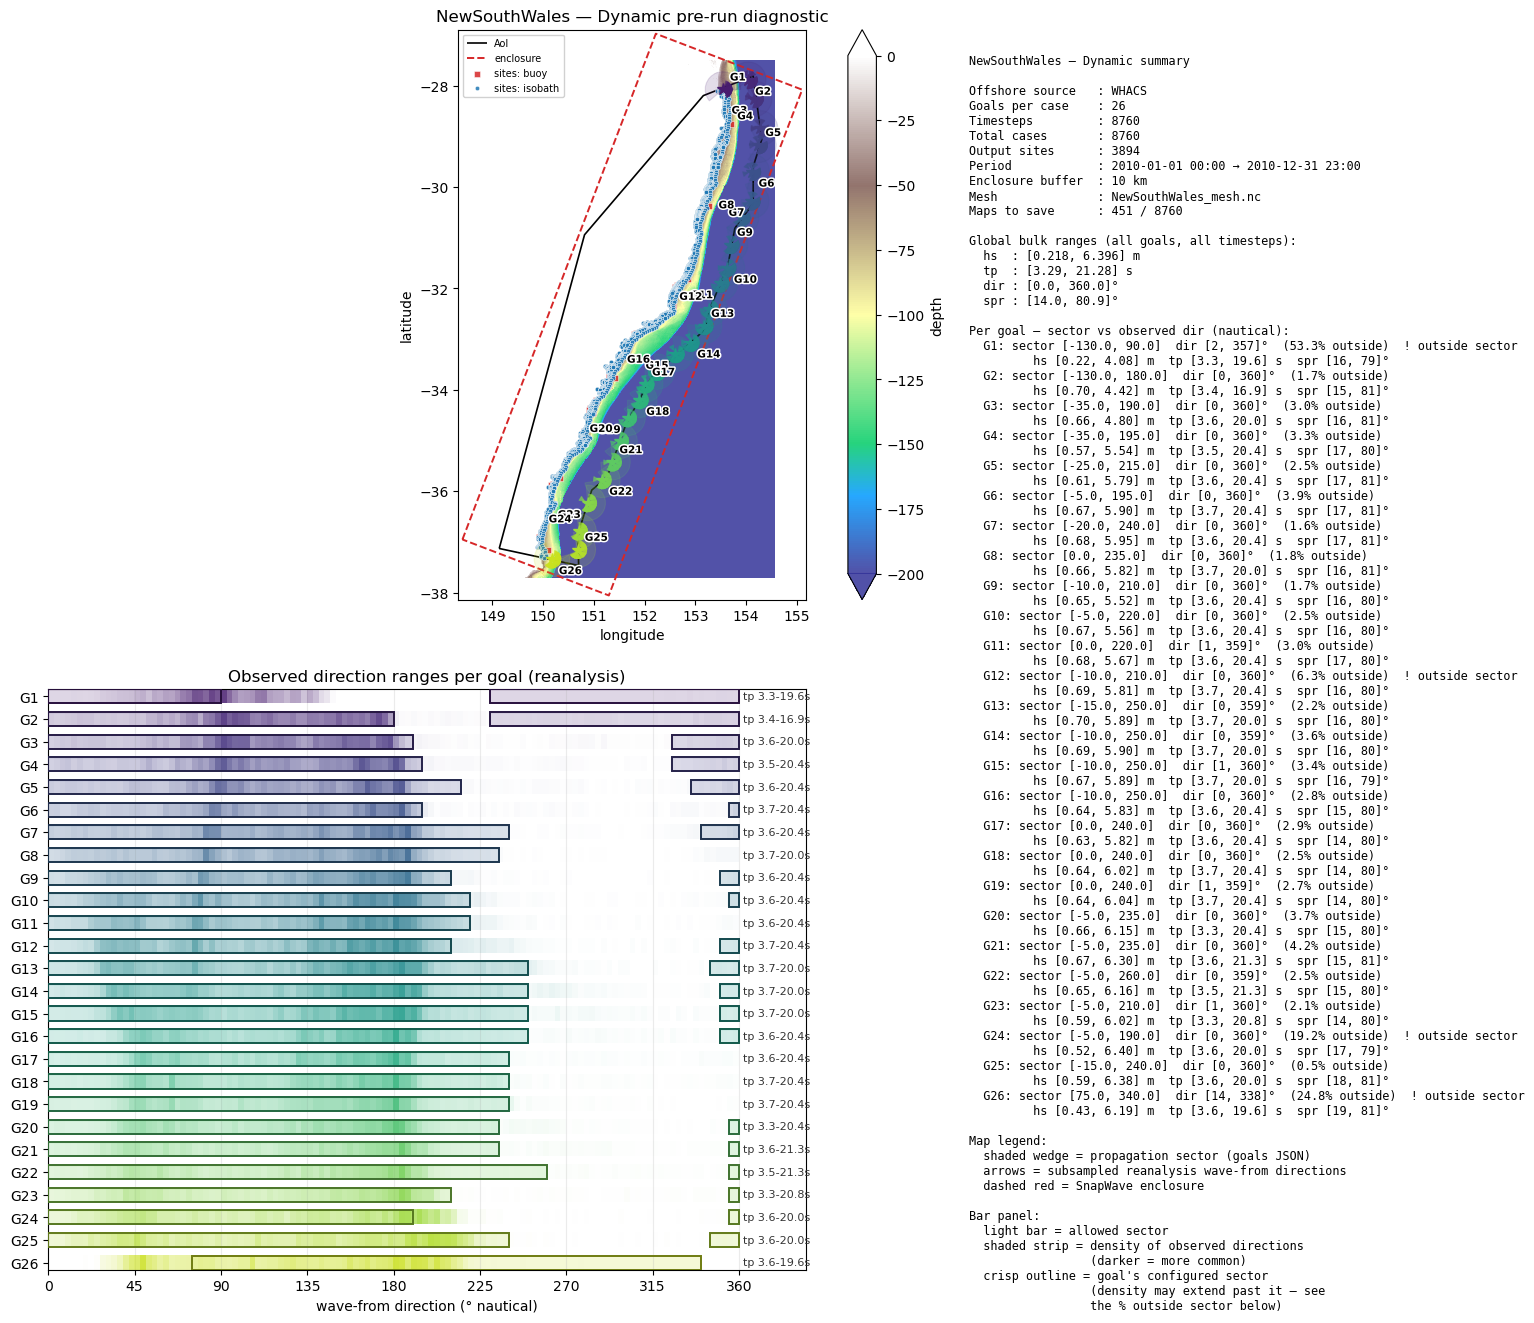

In [7]:
fig = wrapper.plot_configuration(offshore=offshore_ds, offshore_name=offshore_name)
# fig.savefig("dynamic_setup_check.png", dpi=150, bbox_inches="tight")

## Build, run, postprocess

In [8]:
wrapper.load_cases(cases_name_format=lambda ctx: f"{ctx.get('tref')}")

In [9]:
wrapper.cases_dir_to_txt()

'/hyglowdata/NewSouthWales/SnapWave_CASES_Dynamic/case_dirs.txt'

In [10]:
# wrapper.run_cases_in_background(launcher="default", num_workers=1)

In [11]:
wrapper.monitor_cases(value_counts="simple")

Status  
FINISHED    8760
Name: count, dtype: int64

## Inspect finished cases

Post-run diagnostic (reads directly from the case folder):

- top row: full-width domain `tripcolor` map when `save_map=True` for that timestep
- bottom 2×2: `hs`, `tp`, `dir`, `spr` at output sites
- title/subtitle: case id + boundary forcing summary

Customize colormaps via `CasePlotStyle(cmaps={"hs": "viridis", "tp": "plasma", "dir": "twilight_shifted", "spr": "cividis"})`.

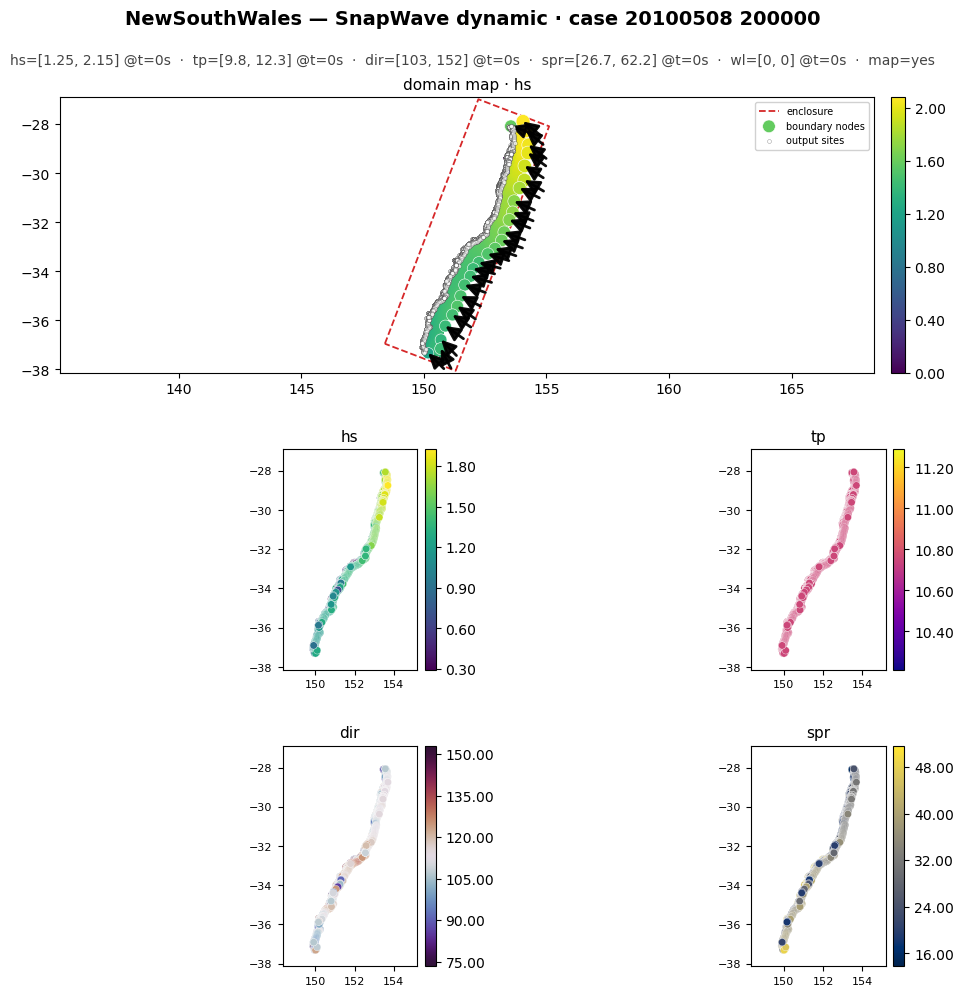

In [12]:
from utils.viz.snapwave_case_plots import CasePlotStyle

style = CasePlotStyle(
    cmaps={"hs": "viridis", "tp": "plasma", "dir": "twilight_shifted", "spr": "cividis"}
)
wrapper.plot_case(
    "/hyglowdata/NewSouthWales/SnapWave_CASES_Dynamic/20100508 200000", style=style
);

In [13]:
result = wrapper.postprocess_cases()
out_nc = cases_dir / f"Dynamic_Cases_{offshore_name}_{period.replace('-', '')}.nc"
result.to_netcdf(out_nc)

In [14]:
import xarray as xr

xr.open_dataset(out_nc).load()

<xarray.Dataset> Size: 546MB
Dimensions:         (time: 8760, sites: 3894)
Coordinates:
  * time            (time) datetime64[ns] 70kB 2010-01-01 ... 2010-12-31T23:0...
  * sites           (sites) <U22 343kB '5m_13' ... 'buoy_Merimbula2_Buoy'
    site_source     (sites) <U7 109kB 'isobath' 'isobath' ... 'buoy' 'buoy'
    site_label      (sites) <U5 78kB '5m' '5m' '5m' ... 'waves' 'waves' 'waves'
    site_depth      (sites) float64 31kB -5.0 -5.0 -5.0 ... -12.81 -13.09 -13.01
    site_longitude  (sites) float64 31kB 153.5 153.5 153.5 ... 150.2 149.9 149.9
    site_latitude   (sites) float64 31kB -28.1 -28.13 -28.16 ... -36.91 -36.91
Data variables:
    hs              (time, sites) float32 136MB 1.329 1.222 ... 1.348 1.344
    tp              (time, sites) float32 136MB 6.474 6.474 ... 6.839 6.839
    dir             (time, sites) float32 136MB 58.92 56.4 23.48 ... 91.19 91.37
    spr             (time, sites) float32 136MB 19.92 18.42 ... 20.51 20.58
Attributes:
    Conventions:                         Conventions = 'CF-1.6, SGRID-0.3
    Build-Revision-Date-Netcdf-library:  4.9.2 of Mar 31 2024 08:09:36 $
    Producer:                            SnapWave
    title:                               Snapwave his point netcdf output